# TP Final DSS · Etapa 2: Método del codo y k-means

**Entrada:** `emse_preprocesado.csv` (sale de la etapa 1). Tiene 47.945 estudiantes con los 15 indicadores en 0/1, el peso muestral y las variables de cruce.

**Qué hace esta etapa**

| Paso | Qué hacemos |
|---|---|
| 1 | Armar la matriz del modelo (solo los 15 indicadores) y los pesos |
| 2 | Método del codo: inercia intra clases para k de 1 a 10 |
| 3 | Coeficiente de silueta como apoyo |
| 4 | Dendrograma (clasificación jerárquica) sobre una muestra, como control |
| 5 | Elegir k |
| 6 | Entrenar el k-means final |
| 7 | Revisar que sea estable |
| 8 | Leer los centroides y ponerle nombre a cada grupo |
| 9 | Gráfico de los grupos y sus centroides en 2 dimensiones |
| 10 | Guardar la base con la columna `perfil` |

## 0. Configuración

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

SEMILLA = 0
TINTA, TINTA_2, GRILLA = '#1B2430', '#52514E', '#E6E4DF'
AZUL, NARANJA, GRIS = '#2A78D6', '#EB6834', '#C9C7C0'

def estilo(ax, titulo, xlabel=None, ylabel=None):
    ax.set_title(titulo, loc='left', fontsize=12, color=TINTA)
    if xlabel: ax.set_xlabel(xlabel, color=TINTA_2)
    if ylabel: ax.set_ylabel(ylabel, color=TINTA_2)
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']:
        ax.spines[lado].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2)
    ax.grid(axis='y', color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)

In [2]:
VARIABLES_MODELO = {
    'soledad':          'Se sintió solo casi siempre',
    'preocupacion':     'La preocupación no lo deja dormir',
    'ideacion':         'Pensó seriamente en el suicidio',
    'plan':             'Hizo un plan',
    'intento':          'Lo intentó',
    'atacado':          'Fue atacado físicamente',
    'peleas':           'Participó en peleas',
    'bullying_escuela': 'Bullying en la escuela',
    'bullying_fuera':   'Bullying fuera de la escuela',
    'ciberacoso':       'Ciberacoso',
    'tabaco':           'Fuma tabaco',
    'alcohol':          'Toma alcohol',
    'borrachera':       'Se emborrachó alguna vez',
    'marihuana':        'Consume marihuana',
    'falta_clases':     'Faltó a clases sin permiso',
}
COLUMNAS_MODELO = list(VARIABLES_MODELO)

RUTA = Path('emse_preprocesado.csv')
if not RUTA.exists():
    try:
        from google.colab import files
        subido = files.upload()          # elegí emse_preprocesado.csv
        RUTA = Path(next(iter(subido)))
    except ImportError:
        raise FileNotFoundError('No encuentro emse_preprocesado.csv (corré antes la etapa 1)')

datos = pd.read_csv(RUTA)
print(f'{len(datos):,} estudiantes'.replace(',', '.'))

47.945 estudiantes


## 1. Matriz del modelo

El k-means solo ve los 15 indicadores. Provincia, escuela, edad, sexo y familia **no entran**: las usamos en la etapa 3 para cruzar.

Cada estudiante es un punto con 15 coordenadas (ceros y unos). Con datos así, la distancia entre dos estudiantes depende de **en cuántas preguntas respondieron distinto**.

In [3]:
X = datos[COLUMNAS_MODELO].to_numpy(dtype=float)
pesos = datos['weight'].to_numpy()
print('Matriz X:', X.shape)

Matriz X: (47945, 15)


## 2. Método del codo

Para cada k entrenamos un k-means y anotamos la **inercia intra clases**: la suma de las distancias (al cuadrado) de cada estudiante al centro de su grupo, ponderada por el peso. Cuanto más baja, más **homogéneos** son los grupos.

La inercia **siempre** baja al agregar grupos (con un grupo por estudiante sería cero), así que no buscamos el mínimo. Buscamos el **codo**: el punto a partir del cual agregar un grupo más ya no mejora mucho.

In [4]:
K_CODO = range(1, 11)
inercias = {}
for k in K_CODO:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X, sample_weight=pesos)
    inercias[k] = modelo.inertia_

codo = pd.DataFrame({'k': list(inercias), 'inercia (millones)': [v / 1e6 for v in inercias.values()]})
codo['baja respecto del k anterior (%)'] = (-codo['inercia (millones)'].pct_change() * 100).round(1)
codo.round(3)

,k,inercia (millones),baja respecto del k anterior (%)
0,1,5.387,NaN
1,2,4.497,16.5
2,3,3.978,11.5
3,4,3.710,6.7
4,5,3.531,4.8
5,6,3.360,4.8
6,7,3.229,3.9
7,8,3.131,3.0
8,9,3.037,3.0
9,10,2.988,1.6


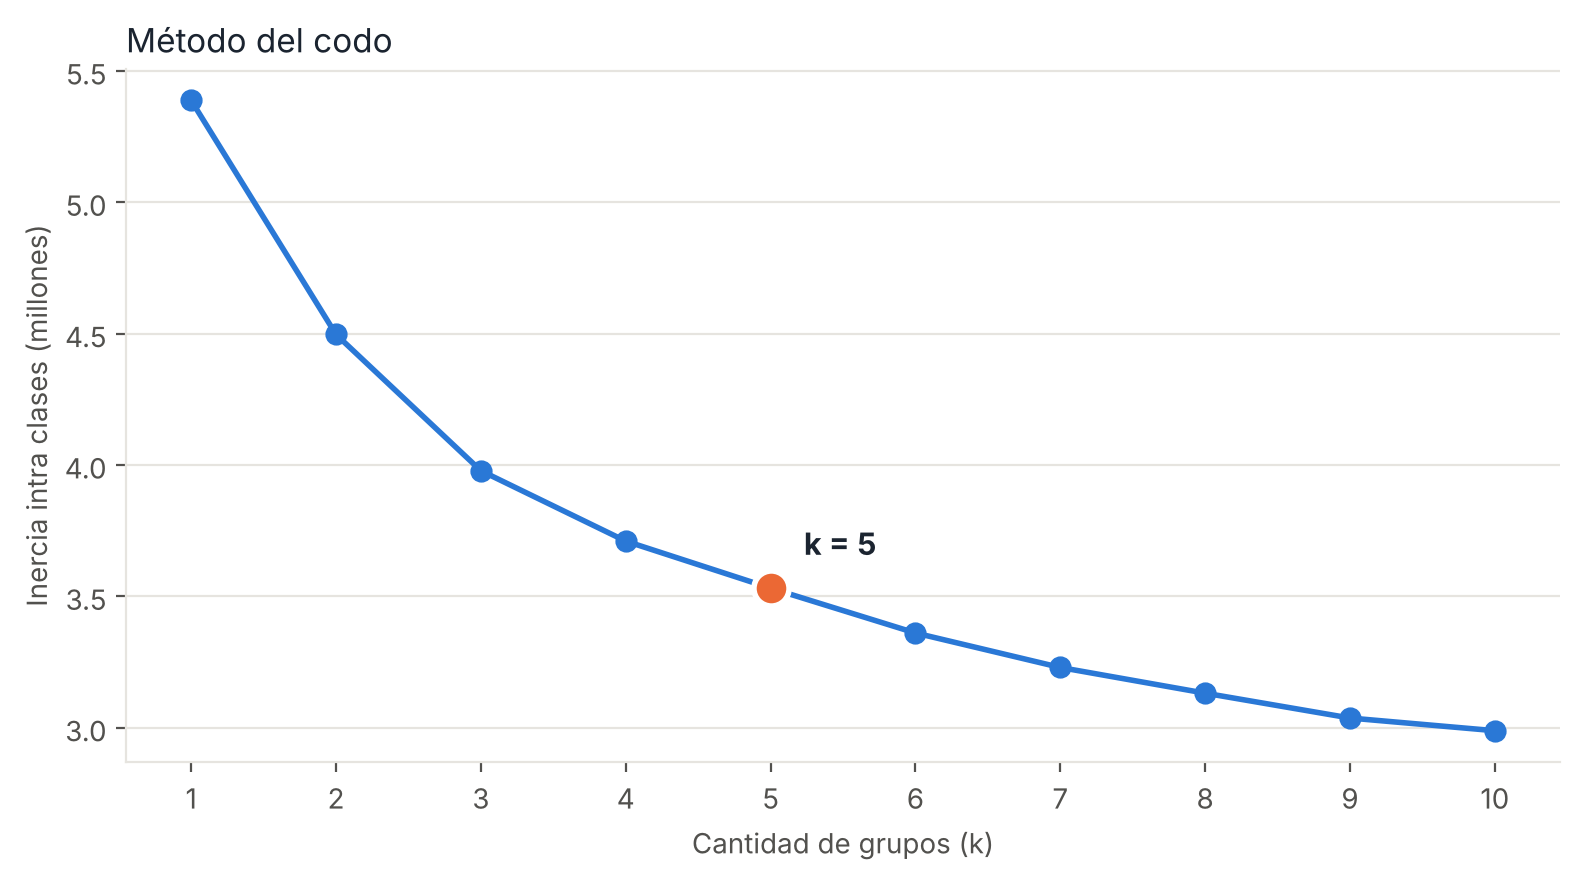

In [5]:
K_ELEGIDO = 5

fig, ax = plt.subplots(figsize=(8, 4.5))
ks, vals = codo['k'], codo['inercia (millones)']
ax.plot(ks, vals, color=AZUL, linewidth=2, marker='o', markersize=7, zorder=3)
fila = codo[codo['k'] == K_ELEGIDO].iloc[0]
ax.scatter([K_ELEGIDO], [fila['inercia (millones)']], s=160, color=NARANJA, zorder=4, edgecolor='white', linewidth=2)
ax.annotate(f'k = {K_ELEGIDO}', (K_ELEGIDO, fila['inercia (millones)']), xytext=(12, 12),
            textcoords='offset points', color=TINTA, fontsize=11, fontweight='bold')
ax.set_xticks(list(ks))
estilo(ax, 'Método del codo', 'Cantidad de grupos (k)', 'Inercia intra clases (millones)')
plt.tight_layout(); plt.show()

**Cómo leerlo.** La caída es fuerte de 1 a 3 grupos, todavía notable de 3 a 4, y a partir de ahí cada grupo nuevo mejora cada vez menos. El codo no es un quiebre limpio sino una curva suave entre 3 y 5, algo común en encuestas con respuestas Sí/No. Por eso el codo nos da un **rango** y la decisión final la toman la silueta, el dendrograma y, sobre todo, la interpretación.

**Pregunta para pensar.** Si la inercia siempre baja, ¿por qué no elegimos k = 10, que tiene la menor?

<details><summary>Ver respuesta</summary>

Porque con muchos grupos se pierden similitudes importantes: el algoritmo empieza a partir en dos grupos que en realidad son el mismo perfil (por ejemplo, "consumo con un poco más de faltas" y "consumo con un poco menos"). Para la decisión eso no sirve, porque dos grupos que piden la misma acción son uno solo. Es el equilibrio que marca el apunte: pocos grupos pierden diferencias, muchos grupos pierden similitudes.
</details>

## 3. Coeficiente de silueta

La silueta mide, para cada estudiante, si está más cerca de su propio grupo que del grupo vecino. Va de -1 a 1: cerca de 1 significa grupos bien separados, cerca de 0 significa grupos que se tocan.

Calcularla necesita la distancia entre todos los pares de estudiantes, así que la estimamos con una muestra de 6.000.

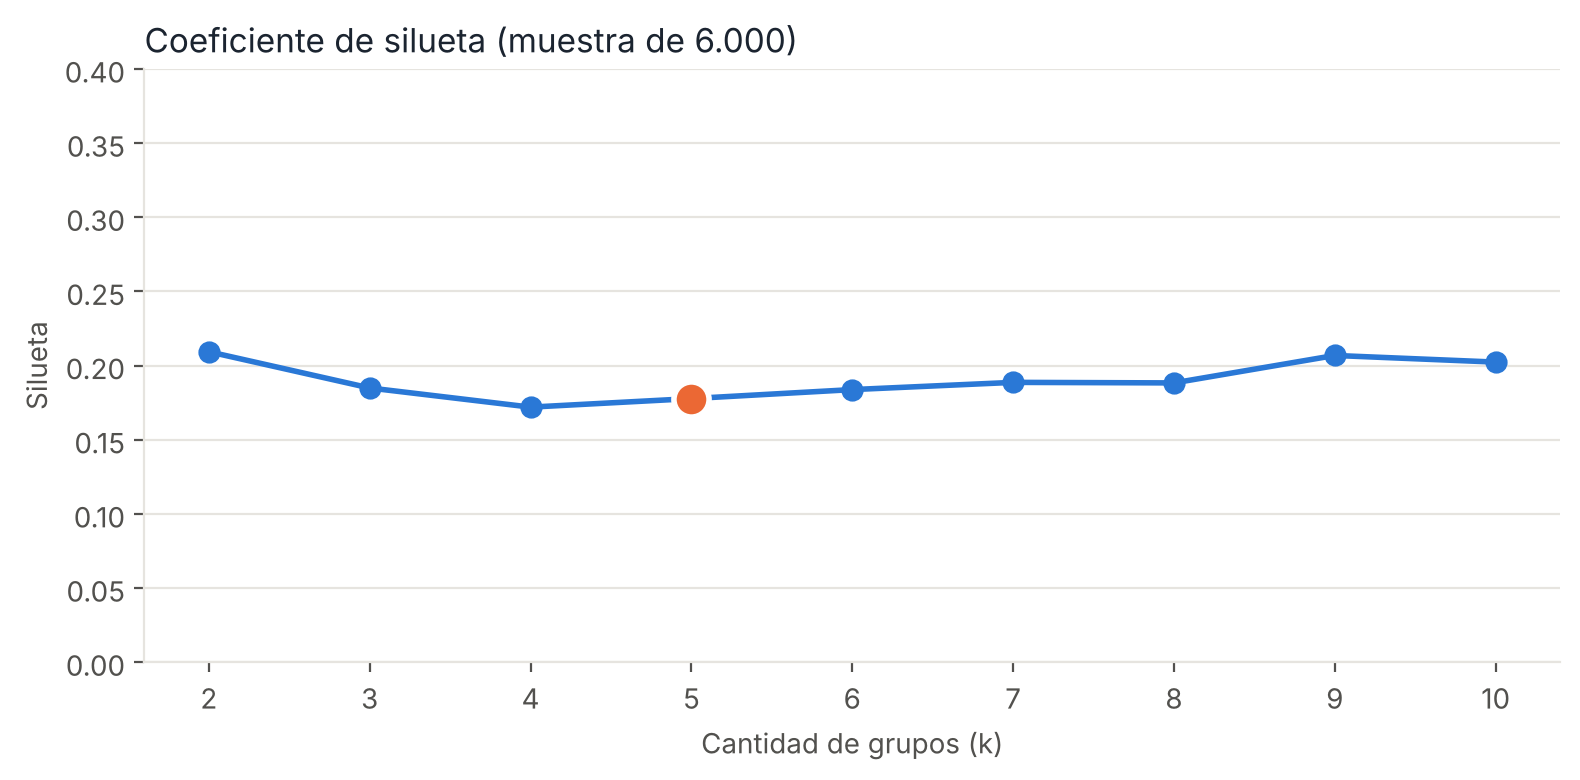

,2,3,4,5,6,7,8,9,10
silueta,0.209,0.185,0.172,0.178,0.184,0.189,0.188,0.207,0.202


In [6]:
rng = np.random.default_rng(SEMILLA)
muestra = rng.choice(len(X), size=6000, replace=False)

siluetas = {}
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X, sample_weight=pesos)
    siluetas[k] = silhouette_score(X[muestra], modelo.labels_[muestra])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(siluetas), list(siluetas.values()), color=AZUL, linewidth=2, marker='o', markersize=7)
ax.scatter([K_ELEGIDO], [siluetas[K_ELEGIDO]], s=160, color=NARANJA, zorder=4, edgecolor='white', linewidth=2)
ax.set_ylim(0, 0.4)
ax.set_xticks(list(siluetas))
estilo(ax, 'Coeficiente de silueta (muestra de 6.000)', 'Cantidad de grupos (k)', 'Silueta')
plt.tight_layout(); plt.show()
pd.Series(siluetas).round(3).rename('silueta').to_frame().T

La silueta da baja y casi plana (alrededor de 0,2 para todos los k). Eso nos dice dos cosas: los grupos **se superponen** (no son cajas cerradas sino perfiles típicos) y la silueta **no alcanza para decidir** el k. Lo vamos a decir así en el informe.

## 4. Dendrograma (clasificación jerárquica)

La clasificación jerárquica del apunte une primero a los estudiantes más parecidos y va formando grupos cada vez más grandes. El dendrograma muestra esa jerarquía, y un **corte** horizontal define cuántos grupos quedan.

No la usamos como modelo final porque con 47.945 estudiantes habría que calcular más de mil millones de distancias. La corremos sobre una muestra de 4.000 como control del k elegido. Usamos el método de Ward, que une en cada paso los dos grupos que menos aumentan la inercia (la misma idea que el k-means).

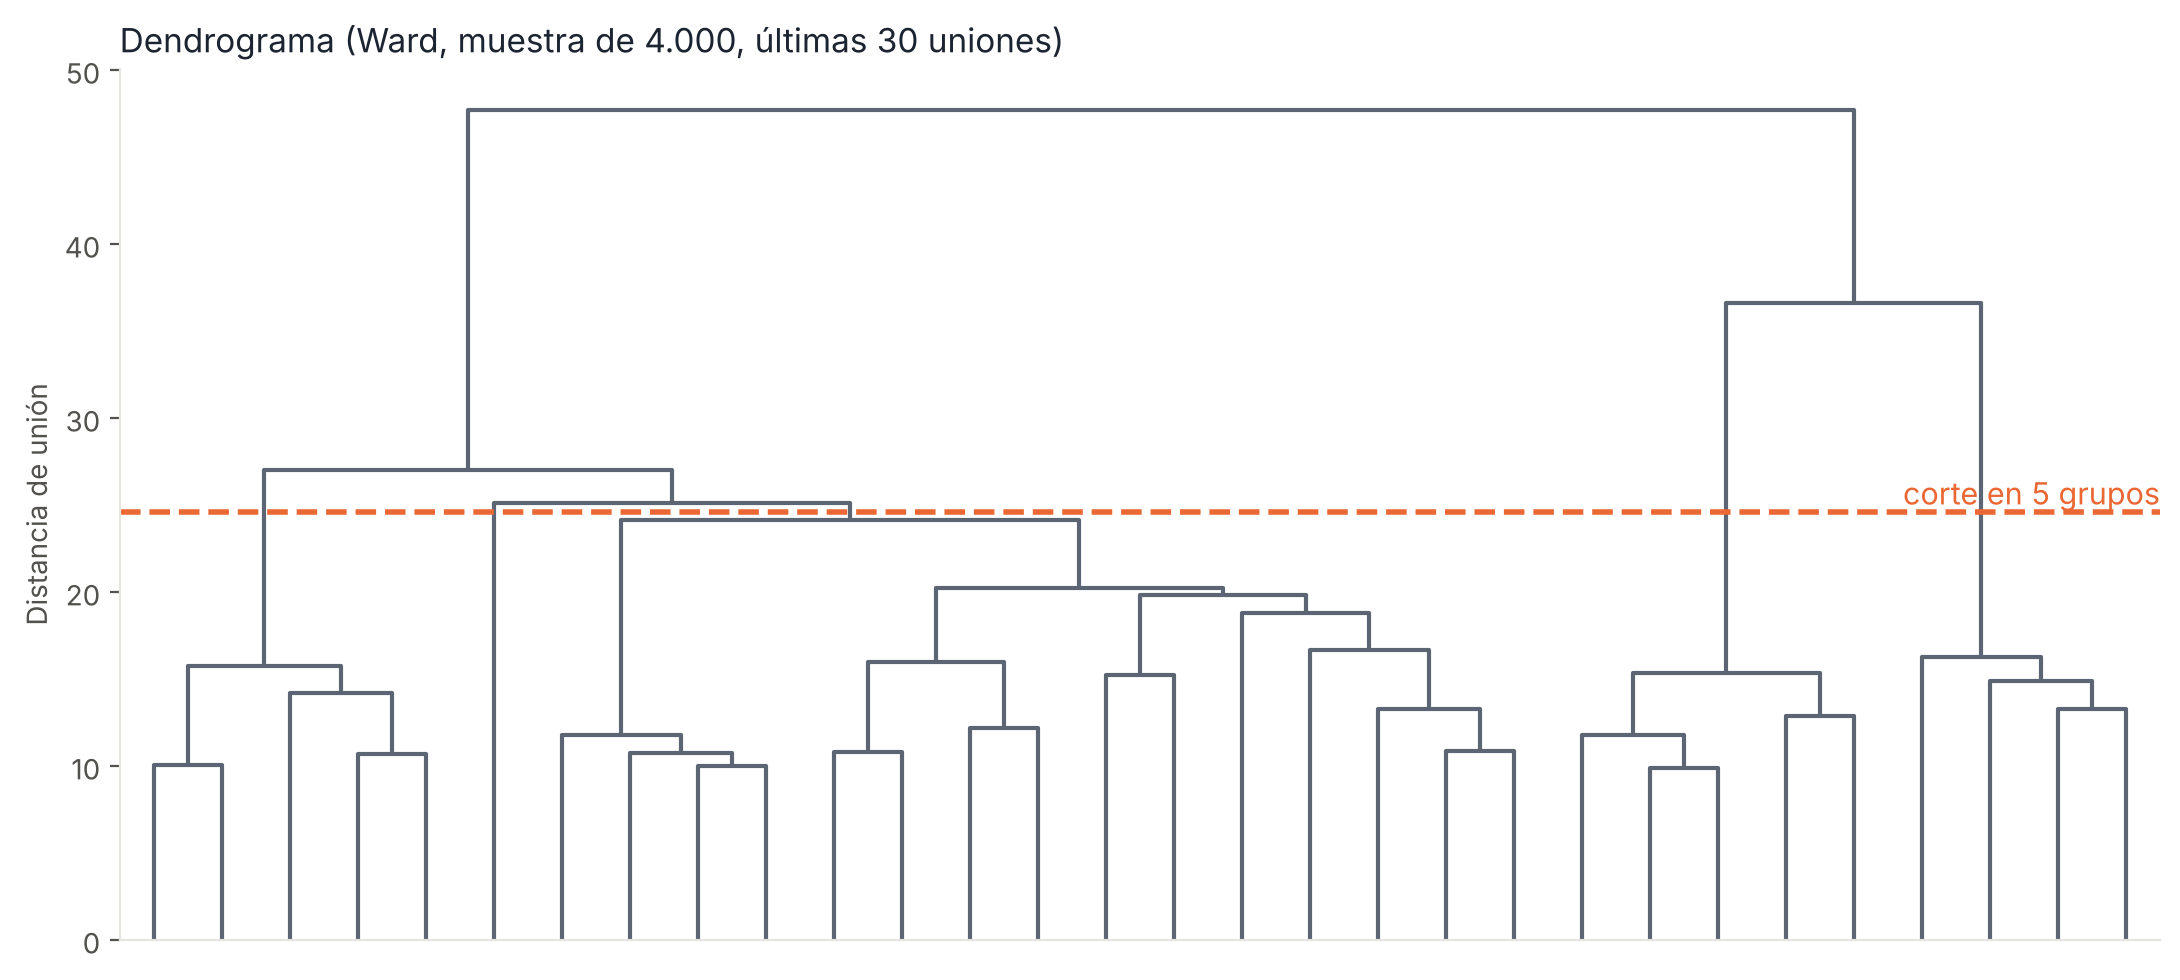

In [7]:
muestra_jer = rng.choice(len(X), size=4000, replace=False)
enlaces = linkage(X[muestra_jer], method='ward')

# altura del corte que deja K_ELEGIDO grupos
alturas = enlaces[:, 2]
corte = (alturas[-K_ELEGIDO] + alturas[-K_ELEGIDO + 1]) / 2

fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(enlaces, truncate_mode='lastp', p=30, ax=ax, no_labels=True,
           link_color_func=lambda _: '#5B6573')
ax.axhline(corte, color=NARANJA, linewidth=2, linestyle='--')
ax.text(ax.get_xlim()[1], corte, f'  corte en {K_ELEGIDO} grupos', color=NARANJA, va='bottom', ha='right', fontsize=11)
estilo(ax, 'Dendrograma (Ward, muestra de 4.000, últimas 30 uniones)', None, 'Distancia de unión')
ax.grid(False)
plt.tight_layout(); plt.show()

**Cómo leerlo.** Las uniones de más arriba son las más "caras": juntan grupos muy distintos. Si cortamos donde las ramas verticales son largas, los grupos que quedan son bien distintos entre sí. El corte en 5 deja grupos que se unen recién a una distancia alta, así que el dendrograma es compatible con elegir 5.

## 5. Elegimos k = 5

* El **codo** marca un rango entre 3 y 5.
* La **silueta** casi no cambia, así que no desempata.
* El **dendrograma** acepta un corte en 5.
* Y lo que decide es la **interpretación**. Con 4 grupos, la violencia entre pares no aparece como grupo propio (queda repartida entre los demás), y es justo una problemática que pide otra acción (convivencia escolar). Con 6, el consumo se parte en tres grupos que terminarían pidiendo la misma acción. Con 5, cada grupo tiene un sentido claro y lleva a una acción distinta (el consumo queda en dos niveles de intensidad).

Si querés comparar, cambiá `K_ELEGIDO` arriba y volvé a correr de acá para abajo.

## 6. Entrenar el k-means final

Siguiendo el procedimiento del apunte (nubes dinámicas): se arranca con centros al azar, se manda cada estudiante al centro más cercano, se recalcula cada centro como el promedio de su grupo y se repite hasta que nadie cambia de grupo.

El problema es el arranque al azar (el apunte lo marca): según dónde arranque, el algoritmo puede quedar atrapado en un **mínimo local**, una solución buena pero no la mejor. Para cuidarnos de eso lo corremos con **8 semillas distintas, cada una con 50 arranques** (`n_init=50`), y nos quedamos con la solución de **menor inercia**, que es lo que el k-means busca minimizar.

In [8]:
corridas = {}
for semilla in range(8):
    corridas[semilla] = KMeans(n_clusters=K_ELEGIDO, n_init=50, random_state=semilla).fit(X, sample_weight=pesos)

mejor = min(corridas, key=lambda s: corridas[s].inertia_)
kmeans = corridas[mejor]
etiquetas = kmeans.labels_
print(f'Mejor semilla: {mejor} · inercia {kmeans.inertia_ / 1e6:.4f} millones · {kmeans.n_iter_} iteraciones hasta converger')

Mejor semilla: 4 · inercia 3.5133 millones · 14 iteraciones hasta converger


## 7. Estabilidad

Comparamos cada corrida contra la mejor con el **índice de Rand ajustado (ARI)**: 1 = mismos grupos (aunque cambie el número de cada uno), 0 = coincidencia al azar. Si varias semillas llegan a la misma inercia y dan ARI cercano a 1, la solución es estable.

In [9]:
estabilidad = pd.DataFrame({
    'inercia (millones)': [round(corridas[s].inertia_ / 1e6, 4) for s in corridas],
    'ARI contra la mejor': [round(adjusted_rand_score(etiquetas, corridas[s].labels_), 3) for s in corridas],
}, index=[f'semilla {s}' for s in corridas])
estabilidad

,inercia (millones),ARI contra la mejor
semilla 0,3.5238,0.788
semilla 1,3.5133,1.000
semilla 2,3.5133,1.000
semilla 3,3.5136,0.987
semilla 4,3.5133,1.000
semilla 5,3.5133,0.999
semilla 6,3.5133,1.000
semilla 7,3.5133,1.000


**Cómo leerlo.** En nuestra corrida casi todas las semillas llegan a la misma inercia y coinciden casi por completo con la mejor. Alguna puede quedar en una inercia apenas mayor: es un mínimo local, y cuando pasa, la diferencia está en **cómo se parte el consumo** (si separa por borracheras o por tabaco y marihuana). Los grupos de malestar, violencia y sin problemáticas salen prácticamente iguales en todas. Por eso nos quedamos con la de menor inercia y lo mencionamos como riesgo en el informe.

**Pregunta para pensar.** ¿Por qué no alcanza con correr el k-means una sola vez?

<details><summary>Ver respuesta</summary>

Porque el resultado depende de los centros con los que arranca. Cada corrida baja la inercia hasta que nadie cambia de grupo, pero puede frenar en un "pozo" que no es el más profundo. Correrlo muchas veces desde arranques distintos y quedarse con la menor inercia es la forma práctica de acercarse a la mejor solución.
</details>

In [10]:
grupos_jer = fcluster(enlaces, t=K_ELEGIDO, criterion='maxclust')
ari_jer = adjusted_rand_score(etiquetas[muestra_jer], grupos_jer)
print(f'Coincidencia con el dendrograma cortado en {K_ELEGIDO} (misma muestra de 4.000): ARI = {ari_jer:.2f}')

Coincidencia con el dendrograma cortado en 5 (misma muestra de 4.000): ARI = 0.21


La coincidencia con el dendrograma es menor porque es otro algoritmo, se calcula sin pesos y sobre una muestra. Que sea mayor a 0 indica que los dos encuentran algo de la misma estructura, pero no que hagan los mismos grupos: es un control, no una validación fuerte.

## 8. Centroides: qué tiene cada grupo

El centroide de cada grupo es el **promedio** de sus estudiantes en cada indicador. Como los indicadores son 0/1, el promedio es directamente el **porcentaje del grupo que respondió que sí**. Es el "estudiante típico" del grupo, y es lo que leemos para ponerle nombre.

El nombre lo ponemos con reglas simples sobre los centroides, para que no dependa del número que el k-means le asignó a cada grupo (ese número cambia con la semilla).

In [11]:
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=COLUMNAS_MODELO)

def nombrar(c: pd.Series) -> str:
    if c['ideacion'] > 0.5:       return 'Malestar emocional'
    if c['bullying_fuera'] > 0.5: return 'Violencia entre pares'
    if c['alcohol'] > 0.5 and c['borrachera'] > 0.5: return 'Consumo de riesgo'
    if c['alcohol'] > 0.5:        return 'Alcohol sin borracheras'
    return 'Sin problemáticas marcadas'

nombres = {i: nombrar(c) for i, c in centroides.iterrows()}
assert len(set(nombres.values())) == K_ELEGIDO, f'Hay nombres repetidos: {nombres}'
centroides.index = [nombres[i] for i in centroides.index]

ORDEN = ['Sin problemáticas marcadas', 'Alcohol sin borracheras', 'Consumo de riesgo', 'Malestar emocional', 'Violencia entre pares']
ORDEN = [g for g in ORDEN if g in centroides.index]
centroides = centroides.loc[ORDEN]

datos['perfil'] = pd.Series(etiquetas).map(nombres).to_numpy()
tamano = pd.DataFrame({
    'estudiantes (muestra)': datos['perfil'].value_counts(),
    '% ponderado': (datos.groupby('perfil')['weight'].sum() / datos['weight'].sum() * 100).round(1),
}).loc[ORDEN]
tamano

,estudiantes (muestra),% ponderado
perfil,,
Sin problemáticas marcadas,17576,37.1
Alcohol sin borracheras,7854,16.1
Consumo de riesgo,10881,22.4
Malestar emocional,6428,13.3
Violencia entre pares,5206,11.0


In [12]:
pais = pd.Series(np.average(X, axis=0, weights=pesos), index=COLUMNAS_MODELO)
tabla_centroides = (centroides.T * 100).clip(lower=0).round(1)   # clip: evita un -0,0 por redondeo
tabla_centroides['Total país'] = (pais * 100).round(1)
tabla_centroides.index = [VARIABLES_MODELO[c] for c in tabla_centroides.index]
tabla_centroides

,Sin problemáticas marcadas,Alcohol sin borracheras,Consumo de riesgo,Malestar emocional,Violencia entre pares,Total país
Se sintió solo casi siempre,7.7,7.2,10.6,58.9,22.2,16.7
La preocupación no lo deja dormir,5.6,7.0,8.9,43.6,17.4,12.9
Pensó seriamente en el suicidio,8.5,8.3,8.8,96.2,16.5,21.1
Hizo un plan,4.9,4.9,6.1,86.5,8.5,16.4
Lo intentó,4.6,4.3,4.5,74.8,7.4,14.2
Fue atacado físicamente,8.2,11.5,15.3,41.7,25.1,16.7
Participó en peleas,12.1,19.2,33.6,40.4,25.8,23.3
Bullying en la escuela,10.5,9.4,8.0,39.3,79.8,21.2
Bullying fuera de la escuela,4.4,8.3,13.9,42.0,83.8,20.9
Ciberacoso,5.3,8.9,15.4,47.3,74.4,21.4


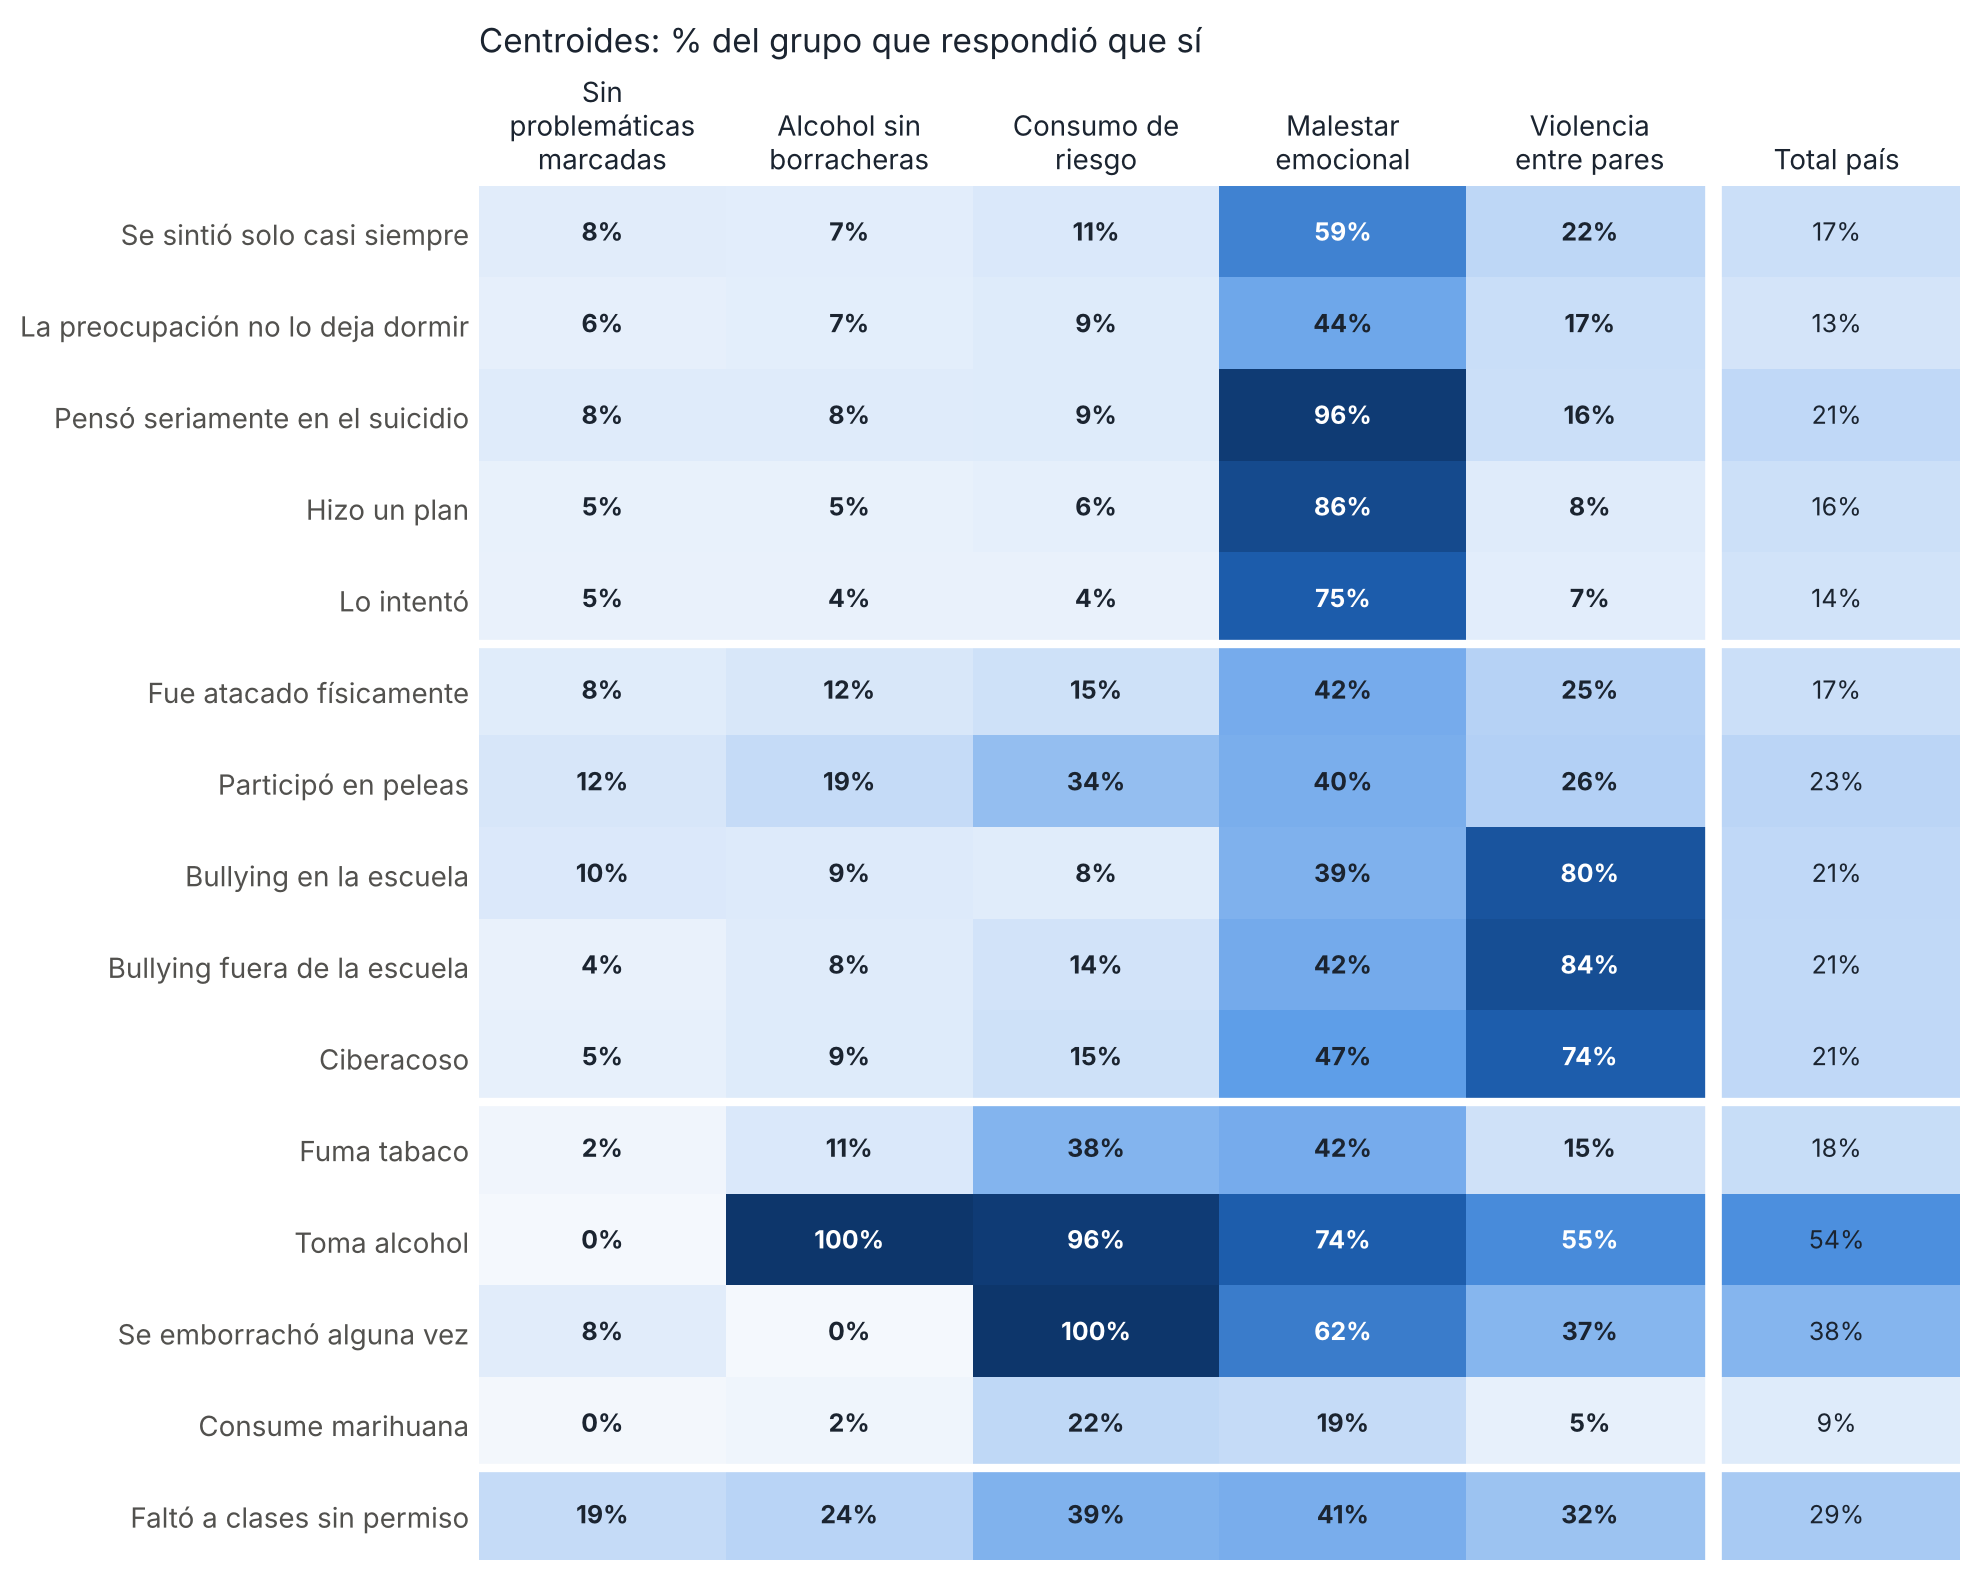

In [13]:
def graficar_centroides(tabla: pd.DataFrame):
    rampa = LinearSegmentedColormap.from_list('azules', ['#F4F8FD', '#B7D3F6', '#5598E7', '#1C5CAB', '#0D366B'])
    fig, ax = plt.subplots(figsize=(10, 8))
    valores = tabla.to_numpy()
    ax.imshow(valores, cmap=rampa, vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(tabla.shape[1]), [textwrap.fill(c, 13) for c in tabla.columns], fontsize=10, color=TINTA)
    ax.set_yticks(range(tabla.shape[0]), tabla.index, fontsize=10, color=TINTA_2)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):
            v = valores[i, j]
            ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=9,
                    color='white' if v >= 55 else TINTA, fontweight='bold' if j < tabla.shape[1] - 1 else 'normal')
    # separadores de dimensiones y de la columna del país
    for corte in [5, 10, 14]:
        ax.axhline(corte - 0.5, color='white', linewidth=3)
    ax.axvline(tabla.shape[1] - 1.5, color='white', linewidth=6)
    ax.set_title('Centroides: % del grupo que respondió que sí', loc='left', fontsize=12, color=TINTA, pad=48)
    plt.tight_layout(); plt.show()

graficar_centroides(tabla_centroides)

**Cómo leerlo.** Cada columna es un grupo y cada fila un indicador. Lo que define a un grupo son las filas donde se aleja de la última columna (el total del país). Por ejemplo, el grupo de consumo de riesgo tiene borracheras, tabaco y marihuana muy por encima del país, y el de malestar emocional tiene las cinco filas de salud mental arriba del 40%.

Fijate que **nadie le dijo al algoritmo** qué variables van juntas. La relación entre columnas aparece sola en el centroide, porque los estudiantes que tienen esas cosas juntas se parecen entre sí y caen en el mismo grupo.

## 9. Gráfico de los grupos y sus centroides

Los estudiantes viven en 15 dimensiones, así que para dibujarlos hay que **proyectarlos a 2**. Usamos PCA (análisis de componentes principales), que busca las dos direcciones en las que los datos más varían.

Dos aclaraciones para leerlo bien:

* Es una **proyección**: grupos que se ven pegados en 2D pueden estar separados en las otras 13 dimensiones. El gráfico sirve para ver la forma general, no para medir distancias.
* Como los datos son 0/1, muchos estudiantes caen exactamente en el mismo punto. Les sumamos un pequeño ruido (jitter) solo para el dibujo, para que se vea dónde hay muchos.

Para que se lean bien los cinco grupos, hacemos un panel por grupo: sus estudiantes en color, el resto en gris, y el centroide marcado.

In [14]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
varianza = pca.explained_variance_ratio_ * 100
print(f'Las 2 componentes explican {varianza.sum():.0f}% de la variación ({varianza[0]:.0f}% + {varianza[1]:.0f}%)')

dib = rng.choice(len(X), size=5000, replace=False)
P = pca.transform(X[dib]) + rng.normal(0, 0.06, size=(len(dib), 2))
perfil_dib = datos['perfil'].to_numpy()[dib]
C2 = pca.transform(centroides.to_numpy())

# qué indicadores pesan en cada componente (para ponerle nombre a los ejes)
cargas = pd.DataFrame(pca.components_.T, index=[VARIABLES_MODELO[c] for c in COLUMNAS_MODELO], columns=['Componente 1', 'Componente 2'])
print('\nIndicadores que más pesan en cada componente:')
for comp in cargas:
    print(f'  {comp}:', ', '.join(cargas[comp].abs().sort_values(ascending=False).index[:4]))

Las 2 componentes explican 37% de la variación (24% + 14%)

Indicadores que más pesan en cada componente:
  Componente 1: Se emborrachó alguna vez, Toma alcohol, Pensó seriamente en el suicidio, Fuma tabaco
  Componente 2: Toma alcohol, Se emborrachó alguna vez, Pensó seriamente en el suicidio, Hizo un plan


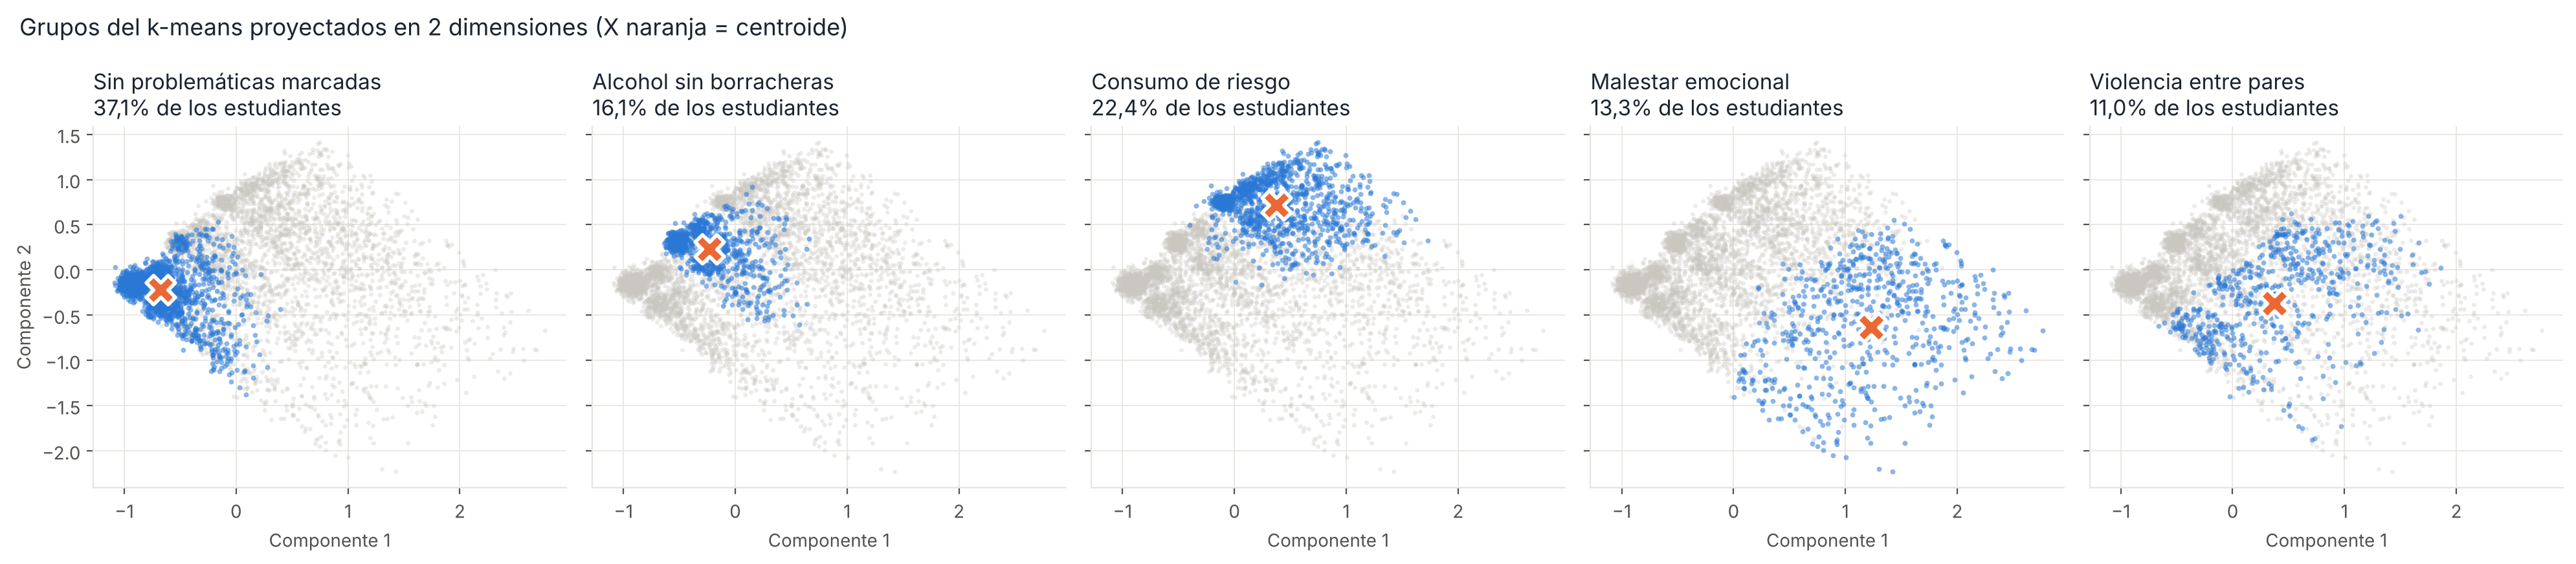

In [15]:
fig, ejes = plt.subplots(1, len(ORDEN), figsize=(4 * len(ORDEN), 4.4), sharex=True, sharey=True)
for ax, (nombre, centro) in zip(ejes, zip(ORDEN, C2)):
    es = perfil_dib == nombre
    ax.scatter(P[~es, 0], P[~es, 1], s=6, color=GRIS, alpha=0.35, linewidth=0)
    ax.scatter(P[es, 0], P[es, 1], s=8, color=AZUL, alpha=0.55, linewidth=0)
    ax.scatter(*centro, s=260, marker='X', color=NARANJA, edgecolor='white', linewidth=2, zorder=5)
    pct = tamano.loc[nombre, '% ponderado']
    estilo(ax, f'{nombre}\n' + f'{pct:.1f}'.replace('.', ',') + '% de los estudiantes')
    ax.grid(color=GRILLA, linewidth=0.6)
ejes[0].set_ylabel('Componente 2', color=TINTA_2)
for ax in ejes:
    ax.set_xlabel('Componente 1', color=TINTA_2)
fig.suptitle('Grupos del k-means proyectados en 2 dimensiones (X naranja = centroide)', x=0.01, ha='left', fontsize=13, color=TINTA)
plt.tight_layout(); plt.show()

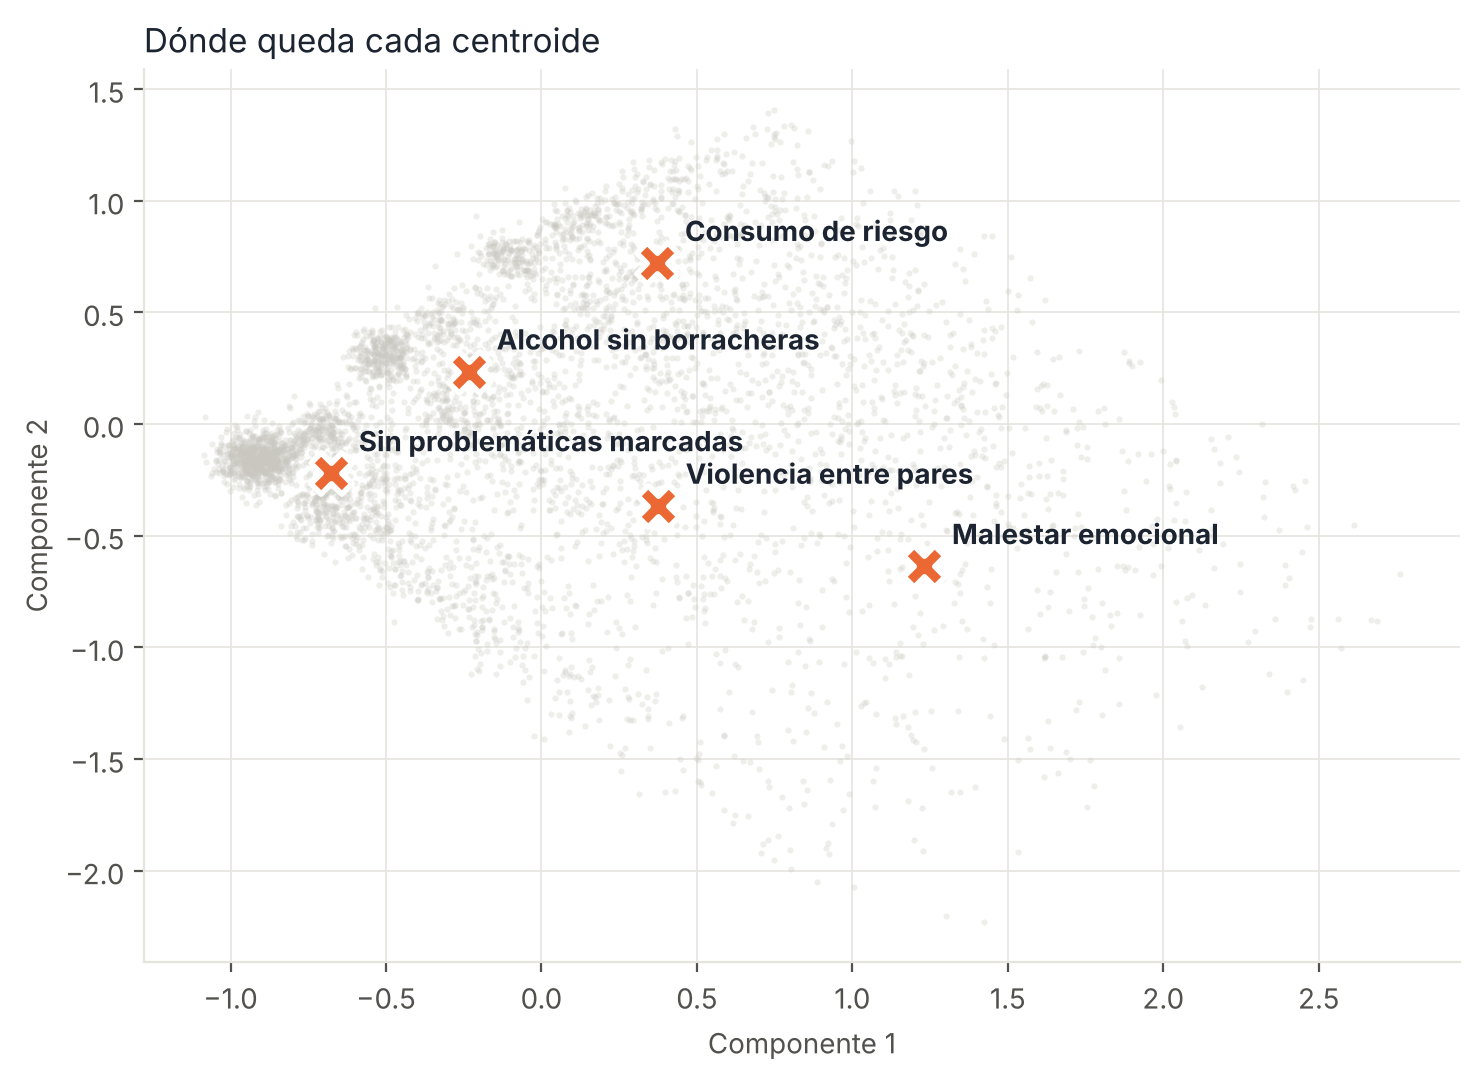

In [16]:
# Todos los centroides juntos en el mismo plano
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(P[:, 0], P[:, 1], s=5, color=GRIS, alpha=0.3, linewidth=0)
for nombre, (x, y) in zip(ORDEN, C2):
    ax.scatter(x, y, s=220, marker='X', color=NARANJA, edgecolor='white', linewidth=2, zorder=5)
    ax.annotate(nombre, (x, y), xytext=(10, 8), textcoords='offset points', fontsize=10, color=TINTA, fontweight='bold')
estilo(ax, 'Dónde queda cada centroide', 'Componente 1', 'Componente 2')
ax.grid(color=GRILLA, linewidth=0.6)
plt.tight_layout(); plt.show()

**Cómo leerlo.** Cada X es el "estudiante típico" de un grupo. Las componentes resumen las direcciones con más variación (arriba se imprimió qué indicadores pesan en cada una), así que la posición de cada centroide dice hacia qué combinación de problemáticas tira su grupo. El grupo sin problemáticas queda en una punta, y los demás se alejan de él en direcciones distintas según el tipo de problema.

## 10. Guardar

In [17]:
datos.to_csv('emse_con_perfil.csv', index=False)
tabla_centroides.to_csv('centroides.csv')
print('Guardados: emse_con_perfil.csv y centroides.csv')
# Para bajarlos desde Colab:
# from google.colab import files; files.download('emse_con_perfil.csv'); files.download('centroides.csv')

Guardados: emse_con_perfil.csv y centroides.csv


## Qué sigue

En la **etapa 3** usamos la columna `perfil` para cruzar los grupos con provincia, edad, sexo, familia y escuela, y armar los rankings por grupo.